# 22. Projeto com o M4 diário: seleção guardada, retomada e custo

**Objetivo e requisitos.** Conduzir um pequeno projeto de previsão com séries reais do M4 diário, do sorteio da amostra à avaliação: preparar a validação temporal, comparar a seleção guardada da AutoHybTS com a escolha pelo menor erro, registrar cada série num banco SQLite (o que permite retomar um projeto interrompido sem refazer o que já terminou) e medir o custo. O projeto usa só o **treino oficial**: os últimos 14 pontos dele ficam selados para a avaliação interna, e o teste oficial não é baixado. Extras `stats` e `plot`; a primeira execução baixa o treino do M4 diário.

In [1]:
import shutil
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment, ExperimentStore
from autohybts.benchmarks import benchmark_cases

warnings.filterwarnings("ignore")
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc4


## 1. Dados e protocolo

A amostra são 3 séries sorteadas com a semente 0 entre as 4227 do M4 diário; ninguém escolhe as séries à mão. De cada uma usamos só o treino oficial, cortado nos últimos 730 dias para controlar o custo. O horizonte é o do M4 diário, 14 passos, previstos de uma vez (protocolo A); o período de escala do MASE é o do M4 (1).

In [2]:
cases = list(benchmark_cases("m4", "daily", 3, 0, development_only=True, development_tail=730))
H = cases[0].horizon
pd.DataFrame(
    [
        {
            "serie": case.series_id,
            "treino_oficial": case.source["original_train_length"],
            "pontos_usados": len(case.values),
            "inicio": case.values.index[0].date(),
            "fim": case.values.index[-1].date(),
        }
        for case in cases
    ]
).set_index("serie")

,treino_oficial,pontos_usados,inicio,fim
serie,,,,
D2692,4197,730,2010-09-26,2012-09-24
D2161,172,172,2002-12-23,2003-06-12
D3594,4197,730,2010-09-26,2012-09-24


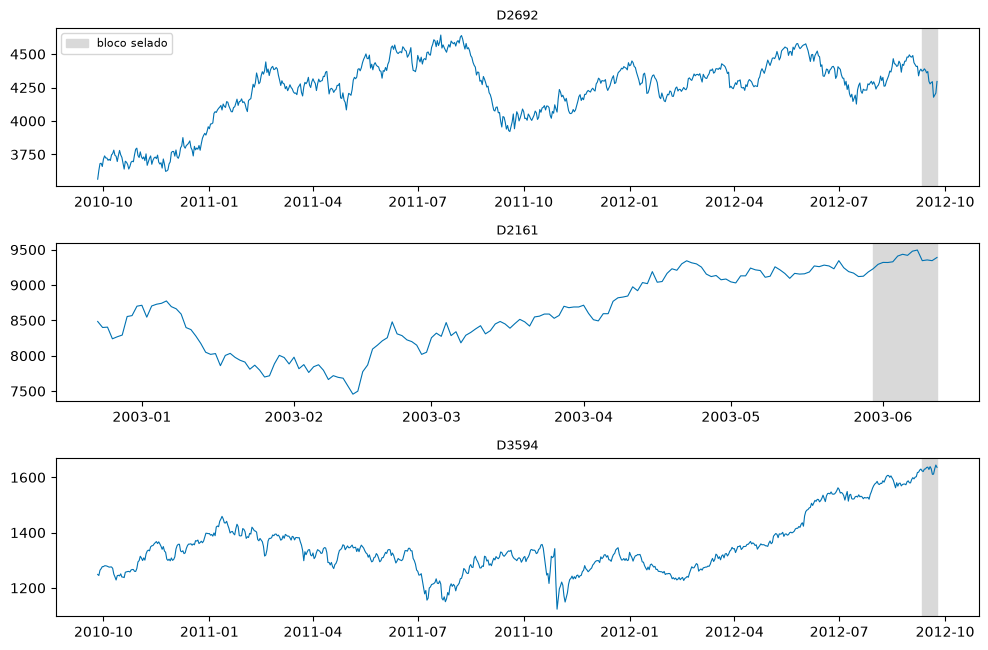

In [3]:
fig, axes = plt.subplots(len(cases), 1, figsize=(10, 2.2 * len(cases)))
for ax, case in zip(axes, cases, strict=True):
    ax.plot(case.values.index, case.values.to_numpy(), linewidth=0.8, color="#0072B2")
    ax.axvspan(case.values.index[-H], case.values.index[-1], color="0.85", label="bloco selado")
    ax.set_title(case.series_id, fontsize=9)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 2. Exploração causal

`fit` não busca nada: valida a série, sela os últimos 14 pontos e fixa as origens de `V_search` e `V_select`. A tabela mostra quantas origens cada série comporta por camada (a regra de aceite foi calibrada com 7) e quantas diferenças o ADF e o KPSS, juntos, pedem no trecho de desenvolvimento.

In [4]:
SETTINGS = {
    "fh": H,
    "seasonal_period": cases[0].seasonal_period,
    "session_id": 42,
    "budget": "small",
    "base_models": ["naive", "random_walk_drift", "linear", "exponential_smoothing"],
    "correctors": ["linear", "knn"],
}
experiments = {case.series_id: AutoHybridExperiment(**SETTINGS).fit(case.values) for case in cases}
pd.DataFrame(
    {
        sid: {
            "pontos_desenvolvimento": len(exp.history_),
            "origens_por_camada": exp.fold_,
            "diferencas_sugeridas": int(exp.stationarity_report()["d_consensus"].iloc[0]),
        }
        for sid, exp in experiments.items()
    }
).T

,pontos_desenvolvimento,origens_por_camada,diferencas_sugeridas
D2692,716,7,1
D2161,158,4,1
D3594,716,7,1


## 3. Controles e modelos propostos

A mesma busca (persistência, passeio aleatório com tendência, regressão linear, suavização exponencial e correções residuais linear e KNN) alimenta três escolhas:

- **seleção guardada** (`compare_models().best`): só aceita complexidade que passa na regra de aceite;
- **menor erro**: a finalista de menor MASE em `V_select`, sem limiar;
- **persistência**: o controle mais simples.

Cada série vira uma execução no banco `artifacts/m4_projeto/m4.db`, apagado no início para a execução ser reproduzível.

In [5]:
folder = Path("artifacts/m4_projeto")
shutil.rmtree(folder, ignore_errors=True)
store = ExperimentStore(folder / "m4.db")
results, seconds = {}, {}


def run_project():
    """Search every series not yet in the database; a finished series is never redone."""
    done = set(store.runs().name) if (folder / "m4.db").exists() else set()
    new = []
    for sid, exp in experiments.items():
        if sid in done:
            continue
        started = time.perf_counter()
        results[sid] = exp.compare_models()
        seconds[sid] = time.perf_counter() - started
        store.log(exp, name=sid, tags={"projeto": "m4-diario"})
        new.append(sid)
    return new

## 4. Busca e seleção

A primeira chamada busca as três séries. A segunda simula a retomada de um projeto interrompido: o banco já tem as três execuções, então nada é refeito.

In [6]:
print("primeira chamada:", run_project())
print("retomada:", run_project())
pd.Series(seconds, name="segundos").round(1)

primeira chamada: ['D2692', 'D2161', 'D3594']
retomada: []


D2692    10.9
D2161     1.4
D3594    10.6
Name: segundos, dtype: float64

## 5. Resultados e gráficos

O banco responde quem venceu em cada série e por quê: cada desafiante comparado com o campeão da vez, com ganho mediano, taxa de vitórias e motivo.

In [7]:
store.query(
    """
    SELECT r.name AS serie, d.family, d.challenger_label AS desafiante, d.accepted AS aceito,
           ROUND(d.median_gain, 3) AS ganho_mediano, ROUND(d.win_rate, 2) AS vitorias,
           d.reason_codes AS motivos
    FROM decisions d JOIN runs r USING (run_id)
    ORDER BY r.name, d.step
    """
)

,serie,family,desafiante,aceito,ganho_mediano,vitorias,motivos
0,D2161,linear,linear(lags=7),0,-0.639,0.00,"[""median_gain_below_threshold"", ""win_rate_belo..."
1,D2161,residual,"naive + linear [w=7, alpha=0.5, historical_oof...",0,0.037,1.00,"[""median_gain_below_threshold""]"
2,D2692,linear,linear(lags=7),0,0.064,0.57,"[""win_rate_below_threshold""]"
3,D2692,residual,"random_walk_drift + linear [w=7, alpha=0.5, hi...",0,-0.008,0.29,"[""median_gain_below_threshold"", ""win_rate_belo..."
4,D3594,linear,linear(lags=7),0,-0.184,0.29,"[""median_gain_below_threshold"", ""win_rate_belo..."
5,D3594,residual,"random_walk_drift + linear [w=7, alpha=1.0, hi...",0,-0.002,0.43,"[""median_gain_below_threshold"", ""win_rate_belo..."


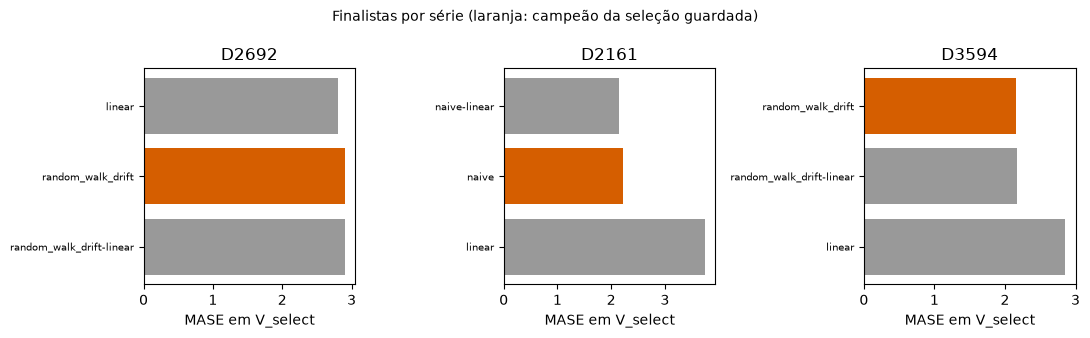

In [8]:
choices = {}
for sid, result in results.items():
    board = result.selection_leaderboard.sort_values("MASE")
    lowest = next(
        r.candidate for r in result.selection.finalists if r.candidate_id == board.index[0]
    )
    choices[sid] = {"guardada": result.best, "menor erro": lowest}

fig, axes = plt.subplots(1, len(results), figsize=(11, 3.4), sharey=False)
for ax, (sid, result) in zip(axes, results.items(), strict=True):
    board = result.selection_leaderboard.sort_values("MASE")
    colors = ["#D55E00" if champion else "0.6" for champion in board.is_champion]
    ax.barh(board.name, board.MASE, color=colors)
    ax.invert_yaxis()
    ax.set(title=sid, xlabel="MASE em V_select")
    ax.tick_params(axis="y", labelsize=7)
fig.suptitle("Finalistas por série (laranja: campeão da seleção guardada)", fontsize=10)
fig.tight_layout()
plt.show()

## 6. Diagnóstico e limites

Uma série curta comporta menos origens que as 7 da calibração da regra de aceite; com menos unidades, a regra aceita estruturas espúrias com mais frequência, e o experimento avisa. Três séries, uma semente e o orçamento `small` dimensionam o projeto, mas não sustentam conclusões sobre o M4 inteiro.

In [9]:
store.query(
    """
    SELECT r.name AS serie, r.n_origins AS origens_duas_camadas, COUNT(l.seq) AS propostas,
           SUM(l.status = 'EVALUATED') AS avaliadas, ROUND(SUM(l.seconds), 1) AS segundos_busca
    FROM runs r JOIN ledger l USING (run_id)
    GROUP BY r.name ORDER BY r.name
    """
)

,serie,origens_duas_camadas,propostas,avaliadas,segundos_busca
0,D2161,8,32,17,1.3
1,D2692,14,32,17,10.5
2,D3594,14,32,17,10.2


## 7. Avaliação interna e custo

Cada escolha é reajustada no desenvolvimento e lida uma única vez no bloco selado de 14 dias. Quando a seleção guardada e o menor erro escolhem a mesma candidata, ela é lida uma vez só.

In [10]:
rows, paths = [], {}
for sid, exp in experiments.items():
    picks = {**choices[sid], "persistência": exp.create_model("naive").candidate}
    read = {}
    for label, spec in picks.items():
        if spec.candidate_id not in read:
            read[spec.candidate_id] = exp.evaluate_external(exp.finalize_model(spec))
        external = read[spec.candidate_id]
        rows.append(
            {
                "serie": sid,
                "escolha": label,
                "modelo": spec.label,
                "MASE": external.metrics["MASE"].iloc[0],
            }
        )
        paths[sid, label] = external.predictions
internal = pd.DataFrame(rows)
internal.pivot(index="serie", columns="escolha", values="MASE").round(3)

escolha,guardada,menor erro,persistência
serie,,,
D2161,2.591,2.509,2.591
D2692,3.366,2.724,3.058
D3594,0.836,0.836,0.791


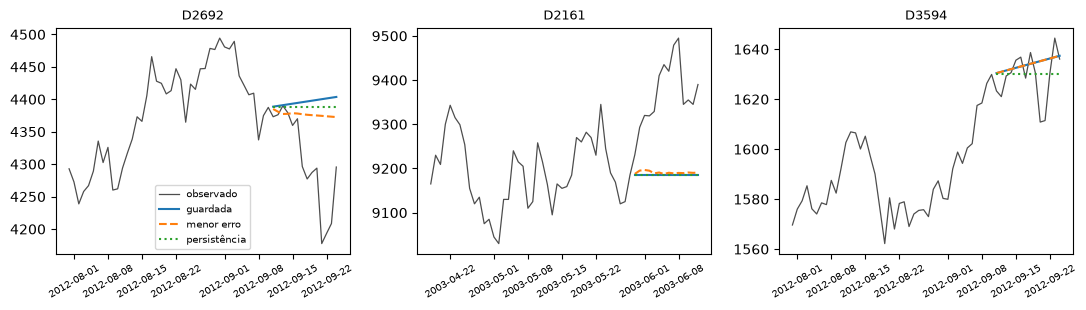

In [11]:
fig, axes = plt.subplots(1, len(cases), figsize=(11, 3.2))
for ax, case in zip(axes, cases, strict=True):
    sid = case.series_id
    recent = case.values.iloc[-4 * H :]
    ax.plot(recent.index, recent.to_numpy(), color="0.3", linewidth=0.9, label="observado")
    for label, style in (("guardada", "-"), ("menor erro", "--"), ("persistência", ":")):
        table = paths[sid, label]
        ax.plot(table.index, table["y_pred"], linestyle=style, label=label)
    ax.set_title(sid, fontsize=9)
    ax.tick_params(axis="x", labelrotation=30, labelsize=7)
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## 8. Leitura

- **Dados.** O sorteio trouxe D2692, D2161 e D3594. A D2161 tem só 172 dias de treino oficial: comporta 4 origens por camada, menos que as 7 da calibração, e o experimento avisou. Nas três séries, o ADF e o KPSS pedem uma diferença.
- **Seleção guardada.** Ficou com um modelo individual nas três: persistência na D2161 e passeio aleatório com tendência nas outras duas. Nenhum desafiante passou na regra de aceite, por motivos diferentes. Na D2161, o híbrido persistência + corretor linear venceu nas 4 unidades, mas com ganho mediano de 3,7 %, abaixo dos 5 %. Na D2692, a regressão linear teve ganho de 6,4 %, mas só 57 % de vitórias, abaixo dos 60 %.
- **Menor erro.** Escolheria esse híbrido na D2161 e a regressão linear na D2692. No bloco selado de 14 dias, essas escolhas tiveram MASE menor que a seleção guardada: 2,51 contra 2,59 e 2,72 contra 3,37. Na D3594 as duas escolheram o mesmo modelo, e a persistência foi a melhor (0,79 contra 0,84).
- **Como ler isso.** Nesta amostra, a cautela da regra não se pagou: as candidatas que ela recusou estavam perto do limiar e acertaram no bloco interno. Mas cada série teve uma única janela de 14 dias, e três séries não sustentam uma comparação. A regra foi calibrada para errar pouco por excesso de complexidade em muitas séries, não para vencer em cada uma. Um estudo com mais séries e sementes é o que decide se ela é conservadora demais no M4 diário.
- **Retomada e custo.** A busca levou cerca de 22 s nas três séries (17 candidatas avaliadas por série, de 32 propostas). A segunda chamada não refez nenhuma, porque o banco já tinha as três execuções: o mesmo mecanismo retoma um projeto maior interrompido no meio.